# P15: does the guide still recognise a painting through a visitor's phone?

Every score so far comes from clean scans: museum B contains named artists' paintings, cropped and evenly lit (ADR 0003
warned that "the real-world score will likely be lower"). A visitor's photo is blurred, compressed, dark, noisy, lit by warm
lamps, crossed by a reflection on the varnish, taken from the side, tilted, or from too far. This notebook measures how the
**final model** (ADR 0012, unchanged: no retraining here) holds up against each of these, one at a time.

**The rules, fixed before any result** (a first scratch run, unsaved, checked the code and the run times):

- Nine perturbations with three levels each (mild, medium, strong), defined in `utils.PERTURBATIONS` and `utils.perturb`.
  Random parts (noise, position of the glare, side of the tilt and rotation) are seeded: the same photos on every run.
- Each perturbation is applied to every painting, then the painting goes through the model exactly as a clean one does.
- **Validation first** (480 paintings of museum A), to read the effects; then **museum B once** (600 paintings, artists never
  seen), to report them. Nothing is chosen or tuned here, so museum B only measures; running the notebook again gives the
  same numbers. The scores go to `results/robustness.csv`.
- With 480 or 600 images, differences of less than about 4 points are noise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    PERTURBATIONS, RESULTS_DIR, final_model, perturb, predict_logits, split_images)

model = final_model()
classes = ["cityscape", "landscape", "portrait", "religious_painting", "still_life"]
LEVELS = ["mild", "medium", "strong"]


def scores(images, labels):
    """Accuracy and predictions of the final model on the clean images and on every perturbation and level."""
    rows, predictions = [], {}
    clean = predict_logits(model, images).argmax(dim=1)
    rows.append({"perturbation": "none", "level": "clean", "value": "", "accuracy": (clean == labels).float().mean().item()})
    predictions[("none", "clean")] = clean
    for kind, values in PERTURBATIONS.items():
        for level, value in zip(LEVELS, values):
            rng = np.random.default_rng(0)  # the same random draws for every run
            predicted = predict_logits(model, [perturb(im, kind, value, rng) for im in images]).argmax(dim=1)
            predictions[(kind, level)] = predicted
            rows.append({"perturbation": kind, "level": level, "value": value,
                         "accuracy": (predicted == labels).float().mean().item()})
    return pd.DataFrame(rows), predictions


print("perturbations and their levels (mild, medium, strong):")
for kind, values in PERTURBATIONS.items():
    print(f"  {kind:11s} {values}")

perturbations and their levels (mild, medium, strong):
  blur        [1, 2, 4]
  jpeg        [30, 15, 5]
  dark        [0.7, 0.5, 0.3]
  noise       [10, 20, 40]
  warm light  [0.1, 0.2, 0.35]
  glare       [0.3, 0.5, 0.7]
  tilt        [0.1, 0.2, 0.3]
  rotation    [5, 10, 20]
  far         [0.8, 0.6, 0.4]


## 1. Validation: what each perturbation costs

About 4 minutes (28 versions of 480 paintings).

In [2]:
val_images, val_labels = split_images("val")
val_scores, val_predictions = scores(val_images, val_labels)
clean_val = val_scores.loc[0, "accuracy"]
val_table = val_scores[val_scores["level"] != "clean"].pivot(index="perturbation", columns="level", values="accuracy")[LEVELS]
val_table["drop at strong (points)"] = 100 * (clean_val - val_table["strong"])
print(f"clean validation accuracy: {clean_val:.1%} (ADR 0012: 83.3%)")
val_table.sort_values("drop at strong (points)").round(3)

clean validation accuracy: 83.3% (ADR 0012: 83.3%)


level,mild,medium,strong,drop at strong (points)
perturbation,,,,
warm light,0.837,0.821,0.823,1.042
glare,0.825,0.810,0.804,2.917
tilt,0.831,0.823,0.802,3.125
dark,0.823,0.812,0.788,4.583
rotation,0.825,0.756,0.656,17.708
noise,0.806,0.779,0.642,19.167
far,0.792,0.758,0.631,20.208
blur,0.802,0.708,0.548,28.542
jpeg,0.792,0.769,0.490,34.375


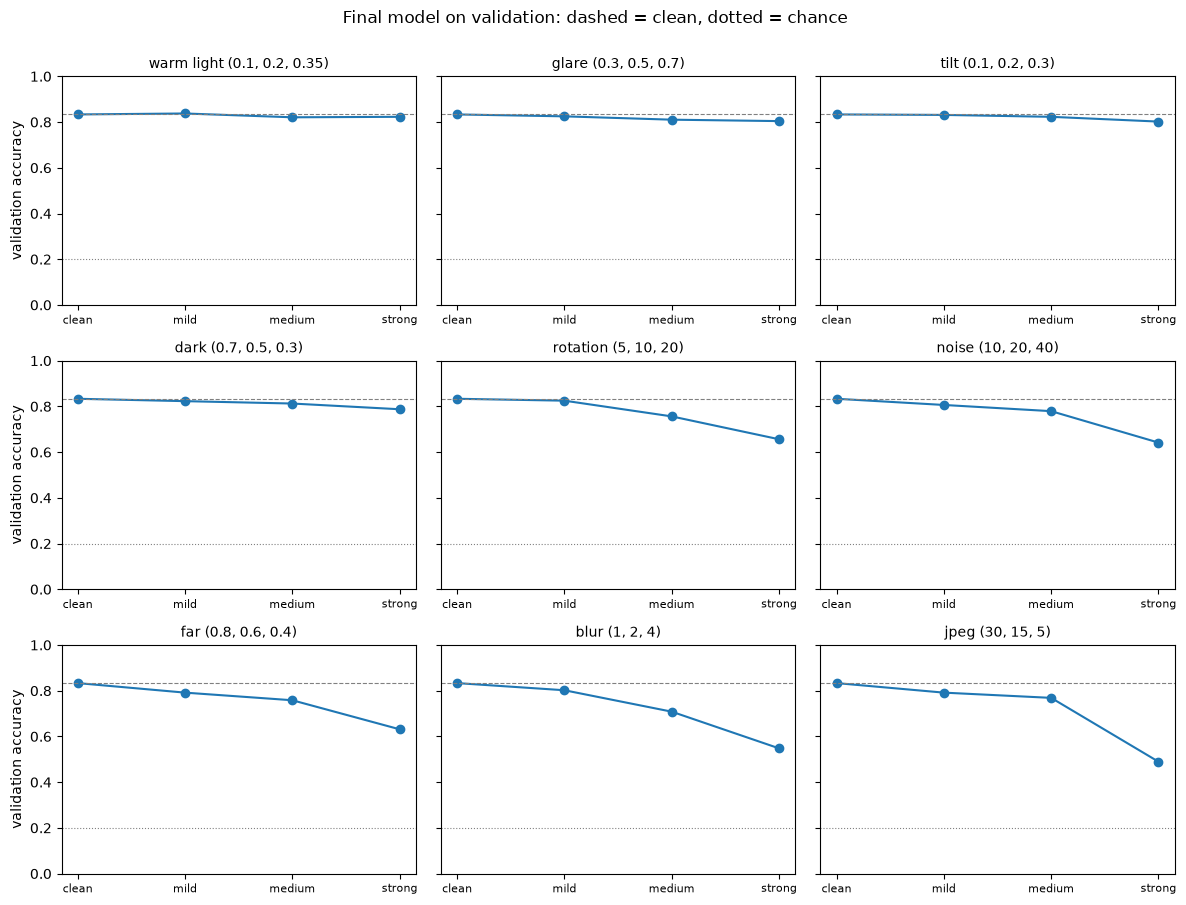

In [3]:
order = val_table.sort_values("drop at strong (points)").index
fig, axes = plt.subplots(3, 3, figsize=(12, 9), sharey=True)
for ax, kind in zip(axes.ravel(), order):
    ax.plot([0, 1, 2, 3], [clean_val, *val_table.loc[kind, LEVELS]], marker="o", color="tab:blue")
    ax.axhline(clean_val, color="grey", linestyle="--", linewidth=0.8)
    ax.axhline(0.2, color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(f"{kind} ({', '.join(str(v) for v in PERTURBATIONS[kind])})", fontsize=10)
    ax.set_xticks([0, 1, 2, 3])
    ax.set_xticklabels(["clean", *LEVELS], fontsize=8)
    ax.set_ylim(0, 1)
for ax in axes[:, 0]:
    ax.set_ylabel("validation accuracy")
fig.suptitle("Final model on validation: dashed = clean, dotted = chance", y=1.0)
plt.tight_layout()
plt.show()

### Where do the predictions go?

When a perturbation hurts, the model may spread its mistakes, or fall back on one genre. Share of each predicted genre,
clean and at the strong level of the five most harmful perturbations (each genre is 20% of the validation paintings).

In [4]:
worst = val_table.sort_values("drop at strong (points)", ascending=False).index[:5]
shares = {"clean": np.bincount(val_predictions[("none", "clean")], minlength=5) / len(val_labels)}
for kind in worst:
    shares[f"{kind}, strong"] = np.bincount(val_predictions[(kind, "strong")], minlength=5) / len(val_labels)
pd.DataFrame(shares, index=classes).T.round(2)

,cityscape,landscape,portrait,religious_painting,still_life
clean,0.17,0.22,0.19,0.19,0.23
"jpeg, strong",0.54,0.03,0.20,0.09,0.14
"blur, strong",0.15,0.42,0.28,0.01,0.14
"far, strong",0.12,0.26,0.14,0.10,0.38
"noise, strong",0.25,0.29,0.21,0.07,0.18
"rotation, strong",0.12,0.32,0.20,0.06,0.30


**What we see.**

- **Light and angle do little.** Warm light, glare, tilt and a dark gallery cost at most 4.6 points even at the strong level (the strong glare covers a large part of the painting with white at 70%; the strong tilt shows it from about 30 degrees to the side). These are within the noise up to the medium level. ImageNet photographs are taken in every light and from every angle, and the pretrained layers seem to have learnt to ignore it.
- **Whatever destroys detail hurts.** At the strong level: rotation by 20 degrees -17.7 points, sensor noise -19.2, a painting filling 40% of the photo -20.2, blur of radius 4 -28.5, JPEG quality 5 -34.4 (49.0%, 2.5 times chance). The medium levels already cost 5 to 12.5 points (blur radius 2: 70.8%). The mild levels stay within about 4 points.
- **The mistakes are not random: each perturbation pushes towards one genre.** Strong JPEG compression sends 54% of the paintings to cityscape (against 17% clean), strong blur 42% to landscape, a distant painting 38% to still life, a rotated one 30% to still life. Our reading, not tested: blocky JPEG edges look like buildings; without detail only the layout of a landscape is left; a small painting alone in a grey frame, or grey corners, look like an object on a plain background.

## 2. Museum B, once

The same 28 versions of the 600 paintings of museum B. About 5 minutes.

In [5]:
test_images, test_labels = split_images("test")
test_scores, _ = scores(test_images, test_labels)
clean_test = test_scores.loc[0, "accuracy"]
print(f"clean museum B accuracy: {clean_test:.1%} (ADR 0012: 86.0%)")

both = val_scores.rename(columns={"accuracy": "validation"}).merge(
    test_scores.rename(columns={"accuracy": "museum B"}), on=["perturbation", "level", "value"])
both.to_csv(RESULTS_DIR / "robustness.csv", index=False)
test_table = test_scores[test_scores["level"] != "clean"].pivot(index="perturbation", columns="level", values="accuracy")[LEVELS]
test_table["drop at strong (points)"] = 100 * (clean_test - test_table["strong"])
test_table["validation drop at strong"] = val_table["drop at strong (points)"]
print("written: results/robustness.csv")
test_table.sort_values("drop at strong (points)").round(3)

clean museum B accuracy: 86.0% (ADR 0012: 86.0%)
written: results/robustness.csv


level,mild,medium,strong,drop at strong (points),validation drop at strong
perturbation,,,,,
glare,0.858,0.855,0.843,1.667,2.917
warm light,0.853,0.853,0.842,1.833,1.042
tilt,0.850,0.850,0.830,3.000,3.125
dark,0.852,0.843,0.818,4.167,4.583
rotation,0.807,0.798,0.687,17.333,17.708
noise,0.853,0.802,0.678,18.167,19.167
far,0.810,0.765,0.632,22.833,20.208
blur,0.835,0.750,0.530,33.000,28.542
jpeg,0.835,0.790,0.503,35.667,34.375


**What we see.**

- **Museum B tells the same story.** Clean: 86.0%, as recorded. The four light and angle perturbations cost 1.7 to 4.2 points at the strong level, and the five that destroy detail 17.3 to 35.7 points, each within 5 points of its validation drop (the largest gap: blur, 33.0 against 28.5). The ranking of the nine is almost the same.
- So the gap seen on clean scans (museum B above validation, ADR 0012) does not protect against bad photos: at the strong level, museum B falls to 50 to 69% for the five harmful perturbations.

## Saved here

`results/robustness.csv`: the accuracy of the final model on validation and on museum B, clean and for each perturbation and
level. No model is trained or chosen; the paintings themselves are never shown (licence).

## What we see

- **The final model is robust to the light and the angle of a visitor's photo** (at most 4.6 points lost on either set), **not to the loss of detail**: blur, heavy JPEG compression, sensor noise, a strong rotation and a distant painting cost 17 to 36 points at the strong level, about the same on validation and museum B.
- **What it means for the kiosk and the phone app, from these measures (none of it built or tested here):** frame the painting (a guide on the camera screen so that it fills the photo: the distance costs 4 to 5 points at 80%, 20 to 23 at 40%); send the photo at a normal JPEG quality (quality 30 already costs 4 points on validation, phones save at 85 to 95); reject or retake blurred photos (a blur of radius 2 costs 11 to 12.5 points); and use the confidence of the model to show two genres when it is unsure (P17).
- **The cure inside the model would be to train with these perturbations** (augmentation during the fine-tuning of the last block). It is not tried here: the final model of ADR 0012 stays as it is.

**Limits.** The perturbations are synthetic, one at a time, with levels chosen before any result but not matched to real phones; a real photo combines several of them, so the real loss may be larger. No real phone photo was tested. Every number has about +/- 4 points of noise (480 or 600 paintings).